# 8. Czas predykcji i złożoność algorytmów dla zbioru Original

Notebook mierzy pięć aktywnych algorytmów aplikacji dla wariantów `full` (111 cech) i `optimized` (74 cechy). Wyniki dotyczą historycznego zbioru Original i nie są łączone z rankingiem URL Corpus.

Metodyka: stały zbiór testowy, `random_state=42`, partie 1/32/256/1000, 10 rozgrzewek i 100 powtórzeń. Deserializacja: 1 rozgrzewka i 30 powtórzeń. Nie występuje trenowanie ani modyfikacja artefaktów.


In [1]:
import importlib
import os
import sys
from pathlib import Path


def locate_backend_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        nested_backend = candidate / 'backend'
        if (candidate / 'config').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
        if (nested_backend / 'config').is_dir() and (nested_backend / 'notebooks').is_dir():
            return nested_backend
    raise FileNotFoundError('Nie znaleziono katalogu backend')


backend_root = locate_backend_root()
notebooks_dir = backend_root / 'notebooks' / 'original'
os.chdir(notebooks_dir)
sys.path.insert(0, str(backend_root))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/phishing-detector-matplotlib')
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])
print(f'Backend: {backend_root}')


Backend: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


In [2]:
import gc
import json
import platform

import numpy as np
import pandas as pd
import psutil
import sklearn
import tensorflow as tf
import xgboost as xgb

from config.project_paths import RESULTS_ROOT
from services.model_repository import ModelRepository
from utils.benchmark_plots import plot_runtime_results
from utils.research_benchmark import (
    algorithm_complexity,
    classifier_probabilities,
    measure_ns,
    timing_summary_ns,
    validate_active_payload,
)

RANDOM_STATE = 42
ALGORITHMS = ('logistic_regression', 'random_forest', 'xgboost', 'svm', 'mlp')
MODES = ('full', 'optimized')
BATCH_SIZES = (1, 32, 256, 1000)
WARMUPS = 10
REPETITIONS = 100
LOAD_WARMUPS = 1
LOAD_REPETITIONS = 30
MODEL_LABELS = {
    'logistic_regression': 'Regresja Logistyczna',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
    'svm': 'SVM',
    'mlp': 'MLP',
}
MODEL_ROOT = backend_root / 'models'
DATA_ROOT = backend_root / 'data' / 'test'
OUTPUT_DIR = RESULTS_ROOT / 'original' / 'runtime_complexity'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Wyniki: {OUTPUT_DIR}')


Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/runtime_complexity


## Walidacja artefaktów i schematów

Każdy aktywny artefakt jest sprawdzany względem nazw oraz kolejności cech w odpowiadającym mu zbiorze testowym. Walidacja obejmuje obecność wymaganego skalera i próg decyzyjny. Błąd kontraktu zatrzymuje obliczenia.


In [3]:
repository = ModelRepository(MODEL_ROOT)
payloads = {}
artifact_files = {}
test_frames = {}
validation_rows = []
for mode in MODES:
    test_frame = pd.read_csv(DATA_ROOT / f'test_dataset_{mode}.csv')
    expected_columns = list(test_frame.columns.drop('phishing'))
    test_frames[mode] = test_frame
    for algorithm in ALGORITHMS:
        payload = repository.load(algorithm, mode, 'current')
        validation = validate_active_payload(payload, expected_columns, algorithm)
        model_path = repository._model_path(algorithm, mode, 'current')
        scaler_path = repository._scaler_path(algorithm, mode, 'current')
        paths = [model_path, *([scaler_path] if scaler_path.exists() else [])]
        payloads[(algorithm, mode)] = payload
        artifact_files[(algorithm, mode)] = paths
        validation_rows.append({
            'algorithm': algorithm,
            'mode': mode,
            'rows': len(test_frame),
            'artifact_bytes': sum(path.stat().st_size for path in paths),
            **validation,
        })
validation_frame = pd.DataFrame(validation_rows)
validation_frame.to_csv(OUTPUT_DIR / 'artifact_validation.csv', index=False)
display(validation_frame)
assert set(validation_frame['features']) == {74, 111}


,algorithm,mode,rows,artifact_bytes,features,threshold
0,logistic_regression,full,40000,6936,111,0.5
1,random_forest,full,40000,131294462,111,0.5
2,xgboost,full,40000,1546661,111,0.5
3,svm,full,40000,5855374,111,0.5
4,mlp,full,40000,253859,111,0.5
5,logistic_regression,optimized,40000,5032,74,0.5
6,random_forest,optimized,40000,125777124,74,0.5
7,xgboost,optimized,40000,1607114,74,0.5
8,svm,optimized,40000,3936836,74,0.5
9,mlp,optimized,40000,252878,74,0.5


## Benchmark predykcji

`classifier-only` mierzy wyłącznie wywołanie algorytmu na gotowej macierzy. `scaler+classifier` obejmuje transformację skalera, gdy artefakt jej wymaga. Surowy czas każdego powtórzenia jest zachowany, dzięki czemu podsumowanie można niezależnie odtworzyć.

In [4]:
raw_rows = []
summary_rows = []
for (algorithm, mode), payload in payloads.items():
    columns = list(payload['feature_names'])
    frame = test_frames[mode][columns]
    scaler = payload.get('scaler')
    prepared = scaler.transform(frame) if scaler is not None else frame
    for batch_size in BATCH_SIZES:
        batch_frame = frame.iloc[:batch_size]
        batch_values = prepared[:batch_size]
        classifier_call = lambda model=payload['model'], values=batch_values: classifier_probabilities(model, values)
        pipeline_call = lambda model=payload['model'], values=batch_frame, transform=scaler: classifier_probabilities(
            model, transform.transform(values) if transform is not None else values
        )
        for scope, operation in (
            ('classifier_only', classifier_call),
            ('scaler_and_classifier', pipeline_call),
        ):
            samples = measure_ns(operation, WARMUPS, REPETITIONS)
            raw_rows.extend({
                'algorithm': algorithm,
                'mode': mode,
                'scope': scope,
                'batch_size': batch_size,
                'repetition': index,
                'duration_ns': duration,
            } for index, duration in enumerate(samples, 1))
            summary_rows.append({
                'algorithm': algorithm,
                'mode': mode,
                'scope': scope,
                'batch_size': batch_size,
                'warmups': WARMUPS,
                'repetitions': REPETITIONS,
                **timing_summary_ns(samples, batch_size),
            })
runtime_raw = pd.DataFrame(raw_rows)
runtime_summary = pd.DataFrame(summary_rows)
runtime_raw.to_csv(OUTPUT_DIR / 'prediction_timing_raw.csv', index=False)
runtime_summary.to_csv(OUTPUT_DIR / 'prediction_timing_summary.csv', index=False)
display(runtime_summary)


,algorithm,mode,scope,batch_size,warmups,repetitions,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,logistic_regression,full,classifier_only,1,10,100,0.040485,0.027020,0.037705,0.112135,0.040485,2.470031e+04
1,logistic_regression,full,scaler_and_classifier,1,10,100,0.554561,0.506854,0.146976,0.902434,0.554561,1.803227e+03
2,logistic_regression,full,classifier_only,32,10,100,0.041381,0.033208,0.036883,0.087381,0.001293,7.732971e+05
3,logistic_regression,full,scaler_and_classifier,32,10,100,0.515462,0.461667,0.137989,0.839856,0.016108,6.208021e+04
4,logistic_regression,full,classifier_only,256,10,100,0.046318,0.046292,0.001266,0.047850,0.000181,5.527023e+06
...,...,...,...,...,...,...,...,...,...,...,...,...
75,mlp,optimized,scaler_and_classifier,32,10,100,1.578937,1.560479,0.056696,1.675702,0.049342,2.026680e+04
76,mlp,optimized,classifier_only,256,10,100,1.336797,1.321416,0.049165,1.437225,0.005222,1.915025e+05
77,mlp,optimized,scaler_and_classifier,256,10,100,1.727405,1.721146,0.037113,1.796875,0.006748,1.481992e+05
78,mlp,optimized,classifier_only,1000,10,100,1.552693,1.549500,0.033654,1.608178,0.001553,6.440423e+05


## Deserializacja i złożoność

Czas deserializacji opisuje koszt przygotowania artefaktu przed pierwszą predykcją. Złożoność nie jest redukowana do jednej arbitralnej liczby: zapisano miary właściwe dla konstrukcji każdego algorytmu.

In [1]:
def deserialize_active(algorithm, mode):
    return ModelRepository(MODEL_ROOT).load(algorithm, mode, 'current')


load_raw_rows = []
load_summary_rows = []
complexity_rows = []
for (algorithm, mode), payload in payloads.items():
    paths = artifact_files[(algorithm, mode)]
    artifact_bytes = sum(path.stat().st_size for path in paths)
    operation = lambda name=algorithm, variant=mode: deserialize_active(name, variant)
    samples = measure_ns(operation, LOAD_WARMUPS, LOAD_REPETITIONS)
    load_raw_rows.extend({
        'algorithm': algorithm,
        'mode': mode,
        'repetition': index,
        'duration_ns': duration,
    } for index, duration in enumerate(samples, 1))
    load_summary_rows.append({
        'algorithm': algorithm,
        'mode': mode,
        'warmups': LOAD_WARMUPS,
        'repetitions': LOAD_REPETITIONS,
        'artifact_bytes': artifact_bytes,
        **timing_summary_ns(samples),
    })
    complexity_rows.append({
        'algorithm': algorithm,
        'mode': mode,
        'artifact_bytes': artifact_bytes,
        **algorithm_complexity(algorithm, payload['model']),
    })
    gc.collect()
load_raw = pd.DataFrame(load_raw_rows)
load_summary = pd.DataFrame(load_summary_rows)
complexity_frame = (
    pd.DataFrame(complexity_rows)
    .melt(
        id_vars=['algorithm', 'mode', 'artifact_bytes'],
        var_name='complexity_measure', value_name='value',
    )
    .dropna(subset=['value'])
)
load_raw.to_csv(OUTPUT_DIR / 'deserialization_timing_raw.csv', index=False)
load_summary.to_csv(OUTPUT_DIR / 'deserialization_timing_summary.csv', index=False)
complexity_frame.to_csv(OUTPUT_DIR / 'algorithm_complexity.csv', index=False)
display(load_summary)
display(complexity_frame)


,algorithm,mode,warmups,repetitions,artifact_bytes,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,logistic_regression,full,1,30,6936,0.070163,0.068604,0.006800,0.078092,0.070163,14252.621057
1,random_forest,full,1,30,131294462,24.470358,23.468083,3.677272,29.750023,24.470358,40.865769
2,xgboost,full,1,30,1546661,1.267801,1.254937,0.067801,1.392419,1.267801,788.767115
3,svm,full,1,30,5855374,0.311038,0.248292,0.159144,0.649406,0.311038,3215.045728
4,mlp,full,1,30,253859,17.584065,17.083104,1.180346,19.879795,17.584065,56.869671
5,logistic_regression,optimized,1,30,5032,0.066200,0.063458,0.006518,0.075748,0.066200,15105.763000
6,random_forest,optimized,1,30,125777124,27.589753,23.850896,12.804965,42.632220,27.589753,36.245341
7,xgboost,optimized,1,30,1607114,1.513038,1.503896,0.140249,1.716865,1.513038,660.922108
8,svm,optimized,1,30,3936836,0.225010,0.202999,0.057054,0.295386,0.225010,4444.252189
9,mlp,optimized,1,30,252878,19.351171,19.058875,0.984691,21.440721,19.351171,51.676460


,algorithm,mode,artifact_bytes,complexity_measure,value
0,logistic_regression,full,6936,coefficients,111.0
1,logistic_regression,optimized,5032,coefficients,74.0
2,logistic_regression,full,6936,intercepts,1.0
3,logistic_regression,optimized,5032,intercepts,1.0
4,logistic_regression,full,6936,trainable_parameters,112.0
5,mlp,full,253859,trainable_parameters,17729.0
6,logistic_regression,optimized,5032,trainable_parameters,75.0
7,mlp,optimized,252878,trainable_parameters,17921.0
8,random_forest,full,131294462,trees,300.0
9,xgboost,full,1546661,trees,200.0


In [6]:
environment = {
    'random_state': RANDOM_STATE,
    'python': platform.python_version(),
    'platform': platform.platform(),
    'processor': platform.processor(),
    'physical_cpu_cores': psutil.cpu_count(logical=False),
    'logical_cpu_cores': psutil.cpu_count(logical=True),
    'memory_bytes': psutil.virtual_memory().total,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__,
    'xgboost': xgb.__version__,
    'tensorflow': tf.__version__,
    'clock': 'time.perf_counter_ns',
    'batch_sizes': list(BATCH_SIZES),
    'prediction_warmups': WARMUPS,
    'prediction_repetitions': REPETITIONS,
    'deserialization_warmups': LOAD_WARMUPS,
    'deserialization_repetitions': LOAD_REPETITIONS,
    'model_source': str(MODEL_ROOT.resolve()),
    'test_source': str(DATA_ROOT.resolve()),
}
(OUTPUT_DIR / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
environment


{'random_state': 42,
 'python': '3.13.8',
 'platform': 'macOS-26.5.2-arm64-arm-64bit-Mach-O',
 'processor': 'arm',
 'physical_cpu_cores': 11,
 'logical_cpu_cores': 11,
 'memory_bytes': 19327352832,
 'numpy': '2.2.6',
 'pandas': '2.3.3',
 'scikit_learn': '1.7.2',
 'xgboost': '3.1.1',
 'tensorflow': '2.21.0',
 'clock': 'time.perf_counter_ns',
 'batch_sizes': [1, 32, 256, 1000],
 'prediction_warmups': 10,
 'prediction_repetitions': 100,
 'deserialization_warmups': 1,
 'deserialization_repetitions': 30,
 'model_source': '/Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend/models',
 'test_source': '/Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend/data/test'}

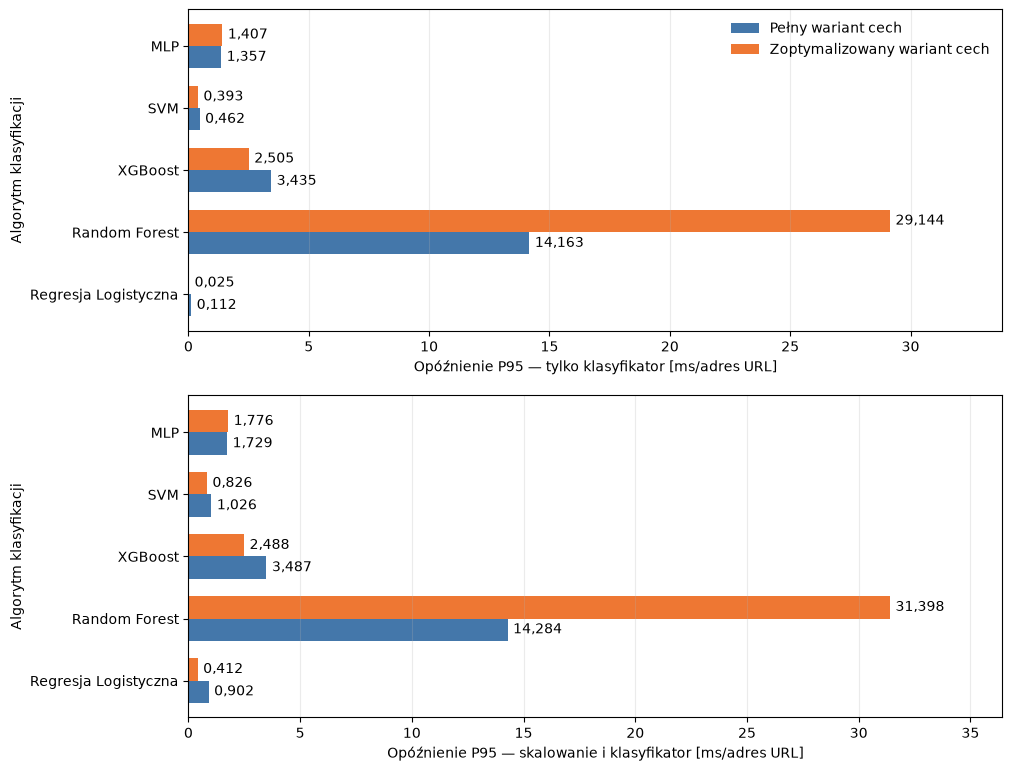

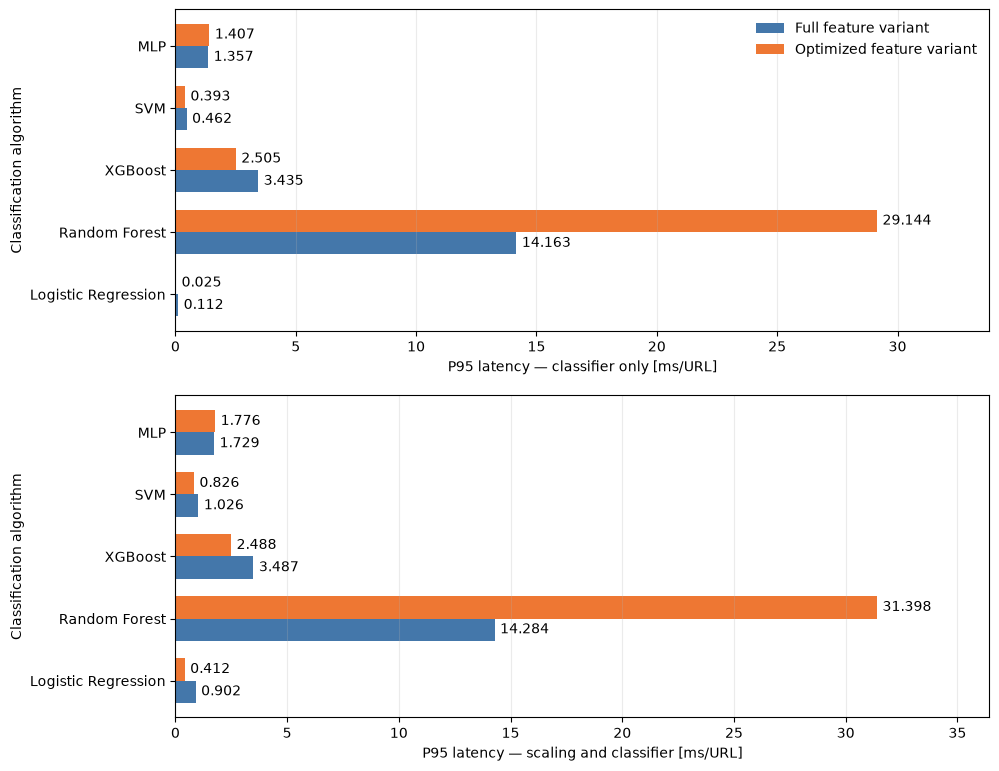

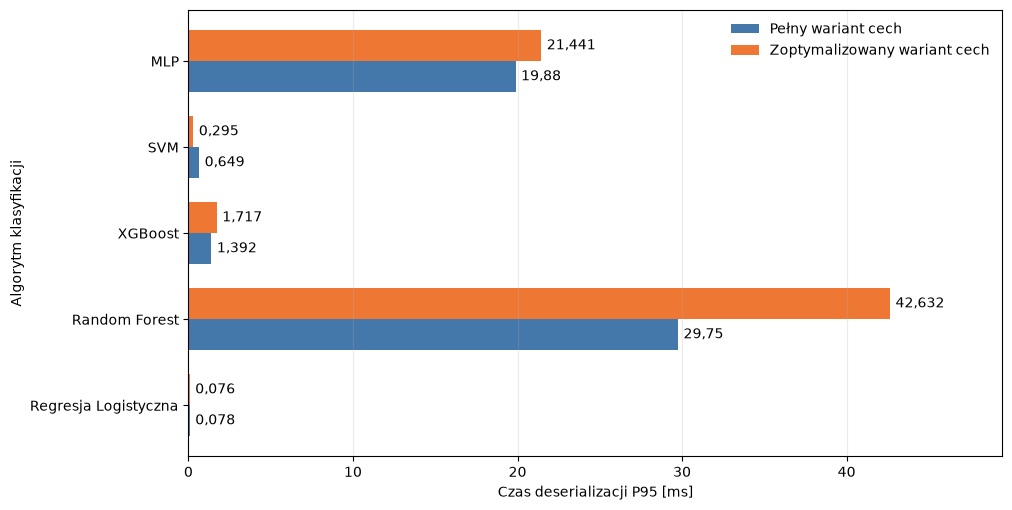

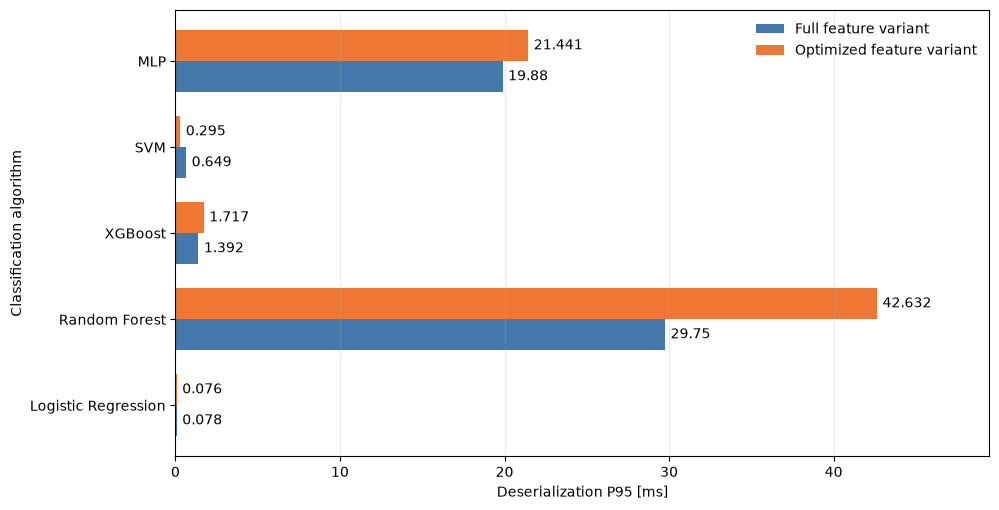

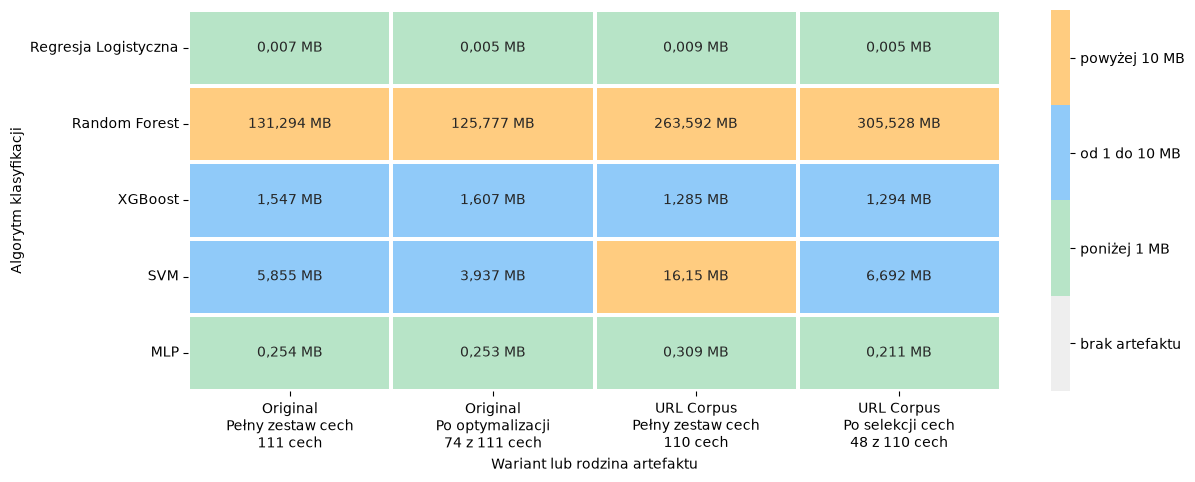

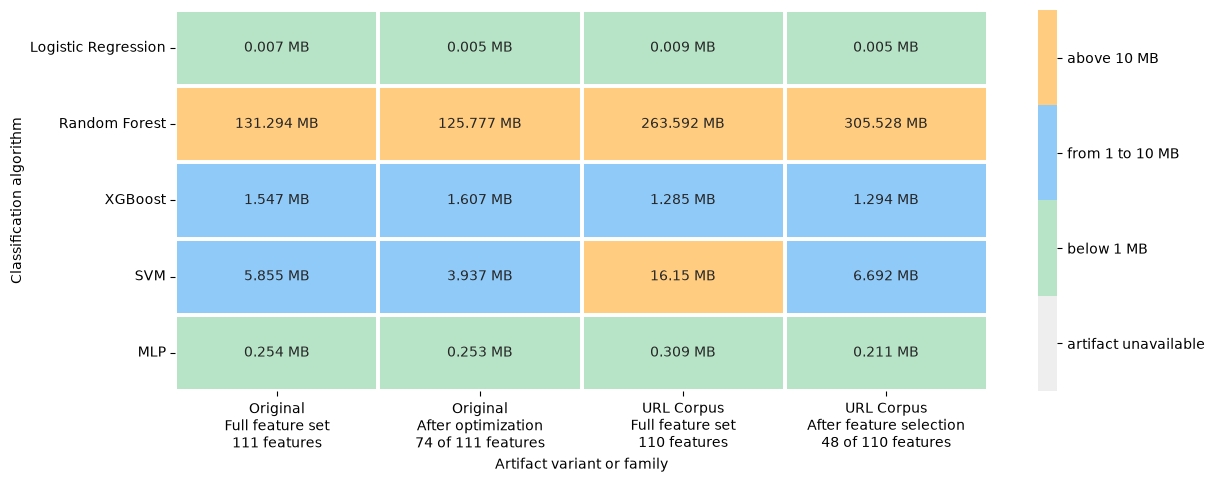

In [1]:
artifact_groups = {
    family: pd.read_csv(
        RESULTS_ROOT / family / 'runtime_complexity' / 'deserialization_timing_summary.csv'
    )
    for family in ('original', 'url_corpus')
}
plot_runtime_results(
    runtime_summary, load_summary, OUTPUT_DIR, MODEL_LABELS, artifact_groups
)
batch_one = runtime_summary[runtime_summary['batch_size'] == 1].copy()


## Interpretacja

- osobne panele wariantów eliminują mieszanie 111 i 74 cech;
- oś logarytmiczna pokazuje różnice między szybkimi i wolnymi algorytmami bez ukrywania małych wartości;
- etykiety liczbowe pozwalają odczytać P95 i rozmiar bez szacowania wysokości słupka;
- `classifier-only` izoluje algorytm, a `scaler_and_classifier` pokazuje koszt przygotowania danych;
- złożoność strukturalna jest raportowana miarami właściwymi dla każdej rodziny algorytmu, bez sztucznego wspólnego rankingu.


In [8]:
fastest = (
    batch_one[batch_one['scope'] == 'scaler_and_classifier']
    .sort_values('p95_ms')
    .iloc[0]
)
smallest = load_summary.sort_values('artifact_bytes').iloc[0]
print(
    f"Najniższe P95 dla jednej URL: {MODEL_LABELS[fastest['algorithm']]} "
    f"({fastest['mode']}), {fastest['p95_ms']:.4f} ms."
)
print(
    f"Najmniejszy artefakt: {MODEL_LABELS[smallest['algorithm']]} "
    f"({smallest['mode']}), {smallest['artifact_bytes'] / 1_000_000:.3f} MB."
)
print('Wnioski dotyczą wyłącznie aktywnych artefaktów Original i tego środowiska.')


Najniższe P95 dla jednej URL: Regresja Logistyczna (optimized), 0.4123 ms.
Najmniejszy artefakt: Regresja Logistyczna (optimized), 0.005 MB.
Wnioski dotyczą wyłącznie aktywnych artefaktów Original i tego środowiska.
